<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/lab-003b-trained-networks-jax.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 003b <br>
<hr/>

# Lab 003b — Trained networks in JAX

Training a network is rarely the last step. A trained network is a set of arrays (the parameters) together with a description of the computation (the architecture), and most of the daily work consists of doing things *with* it: storing it, reloading it, looking at what it has learned, cutting it into pieces, adding layers, and re-using it for a new problem. This lab is the toolbox for these operations.

We train one small **convolutional neural network (CNN)** on the handwritten digits 0–4 of MNIST and then use it in every section. Section 1 trains the CNN once, writes its parameters to disk, loads them into a fresh model, and checks that the predictions are identical. Section 2 inspects the trained model: its layers, parameter shapes and counts, access to single weights, and the distinction between trainable and frozen parameters. Section 3 looks inside the network, at the first-layer kernels drawn as images and at the feature maps of one digit after each convolutional layer, obtained as intermediate outputs. Section 4 performs model surgery: it cuts the network into a feature extractor, attaches a new head, inserts a layer and replaces a layer. Section 5 uses these tools for transfer learning on a new task, the digits 5–9 with few labelled images, comparing a random initialisation, a frozen trained body with a new head, and fine-tuning of all parameters. Section 6 lists every operation of the lab in PyTorch and in JAX/Flax side by side.

The twin notebook **Lab 003a** does exactly the same in PyTorch: same data, same architecture, same sections, same printed quantities. The two can be read side by side.

We use three libraries: **JAX** (arrays, automatic differentiation, compilation), **Flax NNX** (`flax.nnx`, neural-network layers as Python objects) and **optax** (optimisers). The network is a convolutional neural network (CNN): its first layers slide small learned filters over the image, so the same pattern detector is applied everywhere. Its activation function is the rectified linear unit, $\mathrm{ReLU}(z)=\max(0,z)$, and it is trained with Adam (adaptive moment estimation), a gradient-descent optimiser that adapts the step size of every parameter to the recent size of its gradients. JAX compiles the computations with XLA (Accelerated Linear Algebra), a compiler that fuses many array operations into one fast kernel; here everything runs on the central processing unit (CPU), and the same code runs on a graphics processing unit (GPU).

> To run this notebook in Google Colab, follow these steps:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (the first code cell sets `JAX_PLATFORMS=cpu`); the model and the data sets are small enough to finish in a few minutes.
> 2. `jax`, `flax`, `optax`, `orbax-checkpoint`, `numpy` and `matplotlib` are pre-installed in Colab.
> 3. The data are read from `data/MNIST_raw/` (the four `*-ubyte.gz` files). If they are missing, the notebook downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"         # run JAX on the CPU (set before importing jax)
os.environ["CUDA_VISIBLE_DEVICES"] = ""     # hide all GPUs

import gzip, importlib.util, shutil, time, urllib.request
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx
from flax.traverse_util import flatten_dict, unflatten_dict

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
def noframe(ax):                            # image panels: no ticks, no frame
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)

t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6 | devices: [CpuDevice(id=0)]


<hr/>
## 1. Training and saving

### 1.1 The data: two tasks from one data set

MNIST contains $28\times28$ grayscale images of handwritten digits, $60\,000$ for training and $10\,000$ for testing. We split it into two tasks. The **source task** consists of the digits 0–4, with all training images of these digits; the CNN is trained on it in this section. The **target task** consists of the digits 5–9 and is used in Section 5. Its labels are shifted, $5\to0,\dots,9\to4$, so both tasks have 5 classes.

The files are in the raw IDX format: a short big-endian header (a magic number, then the sizes), followed by one byte per pixel; we read them with `gzip` and `numpy`. Pixels are scaled to $[0,1]$.

Flax convolutions expect image arrays in the layout `(N, H, W, C)`: batch size, height, width, channels ("channels last"). Our images are therefore stored as `(N, 28, 28, 1)`. (PyTorch uses `(N, C, H, W)`, see Lab 003a.) `jnp.asarray` copies the arrays once to the default device, here the CPU.

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").astype(np.float32) / 255.0   # (60000, 28, 28)
ytr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").astype(np.float32) / 255.0   # (10000, 28, 28)
yte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)

def task(X, y, digits):
    # images of the given digits as (N, 28, 28, 1) float32 and labels shifted to 0 .. len(digits)-1
    keep = np.isin(y, digits)
    return jnp.asarray(X[keep][:, :, :, None]), jnp.asarray(y[keep] - digits[0])

Xs_tr, ys_tr = task(Xtr_all, ytr_all, [0, 1, 2, 3, 4])     # source task: digits 0-4
Xs_te, ys_te = task(Xte_all, yte_all, [0, 1, 2, 3, 4])
Xt_pool, yt_pool = task(Xtr_all, ytr_all, [5, 6, 7, 8, 9]) # target task: labelled images are drawn from this pool in Section 5
Xt_te, yt_te = task(Xte_all, yte_all, [5, 6, 7, 8, 9])

assert Xs_tr.shape[1:] == (28, 28, 1) and Xs_tr.dtype == jnp.float32
print("source task (digits 0-4): train", Xs_tr.shape, "| test", Xs_te.shape)
print("target task (digits 5-9): pool ", Xt_pool.shape, "| test", Xt_te.shape)
print("pixel range:", float(Xs_tr.min()), "to", float(Xs_tr.max()))

source task (digits 0-4): train (30596, 28, 28, 1) | test (5139, 28, 28, 1)
target task (digits 5-9): pool  (29404, 28, 28, 1) | test (4861, 28, 28, 1)
pixel range: 0.0 to 1.0


### 1.2 The architecture: a convolutional body and a dense head

The network (conv–pool–conv–pool–dense–output) is split into two named parts, because Sections 4 and 5 treat them separately. The **body** (the convolutional feature extractor) maps an image to a feature vector of $7\cdot7\cdot32=1568$ numbers,
$$
(N,28,28,1)\xrightarrow{\text{conv }5\times5,\ 16}(N,28,28,16)\xrightarrow{\text{ReLU, max-pool }2}(N,14,14,16)\xrightarrow{\text{conv }3\times3,\ 32}(N,14,14,32)\xrightarrow{\text{ReLU, max-pool }2}(N,7,7,32)\xrightarrow{\text{flatten}}(N,1568).
$$
The **head** (the classifier) is a dense layer with ReLU followed by an output layer, $(N,1568)\xrightarrow{\text{fc, ReLU}}(N,64)\xrightarrow{\text{out}}(N,5)$, giving 5 logits (unnormalised log-probabilities of the classes).

In Flax NNX a network is a Python class derived from `nnx.Module`: layers are created in `__init__` and stored as attributes, and `__call__` is the forward pass. The attribute names (`body`, `conv1`, …) become the parameter names (`body/conv1/kernel`). `padding="SAME"` keeps height and width unchanged, so only pooling halves them. Every layer with parameters receives `rngs`, an `nnx.Rngs(seed)` key generator: JAX has no hidden global random state, and a fixed seed fixes the initial parameters.

The pooling operations have no parameters; they are stored as attributes anyway (`self.pool1 = partial(nnx.max_pool, ...)`, a function with fixed arguments) so that they can be replaced in Section 4.4, like the named `pool1` layer of the PyTorch model.

In [3]:
pool2x2 = partial(nnx.max_pool, window_shape=(2, 2), strides=(2, 2))

class Body(nnx.Module):
    def __init__(self, *, rngs):
        self.conv1 = nnx.Conv(1, 16, kernel_size=(5, 5), padding="SAME", rngs=rngs)   # (N,28,28,1)  -> (N,28,28,16)
        self.pool1 = pool2x2                                                          # -> (N,14,14,16)
        self.conv2 = nnx.Conv(16, 32, kernel_size=(3, 3), padding="SAME", rngs=rngs)  # -> (N,14,14,32)
        self.pool2 = pool2x2                                                          # -> (N,7,7,32)

    def __call__(self, x):
        x = self.pool1(nnx.relu(self.conv1(x)))
        x = self.pool2(nnx.relu(self.conv2(x)))
        return x.reshape(x.shape[0], -1)          # flatten -> (N,1568), order (row, column, channel)

class Head(nnx.Module):
    def __init__(self, n_classes, *, rngs):
        self.fc = nnx.Linear(7 * 7 * 32, 64, rngs=rngs)         # (N,1568) -> (N,64)
        self.out = nnx.Linear(64, n_classes, rngs=rngs)         # (N,64) -> (N,n_classes) logits

    def __call__(self, h):
        return self.out(nnx.relu(self.fc(h)))

class SmallCNN(nnx.Module):
    def __init__(self, n_classes=5, *, rngs):
        self.body = Body(rngs=rngs)
        self.head = Head(n_classes, rngs=rngs)

    def __call__(self, x):
        return self.head(self.body(x))

model = SmallCNN(rngs=nnx.Rngs(0))
out = model(Xs_tr[:8])
assert out.shape == (8, 5) and model.body(Xs_tr[:8]).shape == (8, 1568)
print("logits of 8 images:", out.shape, "| feature vectors:", model.body(Xs_tr[:8]).shape)

logits of 8 images: (8, 5) | feature vectors: (8, 1568)


### 1.3 Training on the source task

Standard supervised training: cross-entropy loss on the logits, Adam with learning rate $10^{-3}$, minibatches of 128 images, one epoch (one pass over the $30\,596$ training images, 239 steps). The minibatch order comes from a NumPy generator with a fixed seed, exactly as in Lab 003a, so both notebooks see the same sequence of minibatches. (The initial parameters differ: the two libraries use different random generators and different default initialisations; Flax draws convolution and dense kernels from a normal distribution with variance $1/\text{fan-in}$ and sets biases to zero, PyTorch draws both from uniform distributions.)

The training step is built from three NNX components. `nnx.Optimizer(model, optax.adam(lr), wrt=nnx.Param)` holds the optax optimiser and its state (Adam's running averages); `wrt` ("with respect to") says *which* variables it updates — here all parameters. This argument is the key to freezing in Section 5.
`nnx.value_and_grad(loss_fn, argnums=nnx.DiffState(0, wrt))(model)` returns the loss and its gradient with respect to the variables of `model` selected by the filter `wrt`.
Finally, `nnx.jit` compiles the whole step (forward pass, gradient, Adam update) with XLA; the first call traces and compiles, later calls with the same shapes reuse the compiled code. `optimizer.update(model, grads)` changes the model's parameters in place, also inside `nnx.jit`.

`make_train_step(wrt)` builds such a step for a given filter; `accuracy` evaluates in chunks of 2000 images.

In [4]:
def make_train_step(wrt):
    # one compiled Adam step that differentiates (and updates) only the variables selected by `wrt`
    @nnx.jit
    def train_step(model, optimizer, xb, yb):
        def loss_fn(model):
            logits = model(xb)
            return optax.softmax_cross_entropy_with_integer_labels(logits, yb).mean()
        loss, grads = nnx.value_and_grad(loss_fn, argnums=nnx.DiffState(0, wrt))(model)
        optimizer.update(model, grads)
        return loss
    return train_step

step_all = make_train_step(nnx.Param)            # all parameters

@nnx.jit
def predict(model, x):
    return model(x).argmax(axis=-1)

def accuracy(model, X, y, chunk=2000):
    # fraction of correctly classified images
    pred = jnp.concatenate([predict(model, X[i:i + chunk]) for i in range(0, len(X), chunk)])
    return float((pred == y).mean())

def train_epochs(model, X, y, epochs, batch_size, lr, seed):
    # plain training loop: one random permutation of the data per epoch
    optimizer = nnx.Optimizer(model, optax.adam(lr), wrt=nnx.Param)
    rng = np.random.default_rng(seed)
    n_batches = len(X) // batch_size                  # the last incomplete batch is dropped
    for epoch in range(epochs):
        perm = rng.permutation(len(X))[: n_batches * batch_size].reshape(n_batches, batch_size)
        losses = [step_all(model, optimizer, X[idx], y[idx]) for idx in perm]
        print(f"epoch {epoch + 1}: mean training loss {float(jnp.mean(jnp.stack(losses))):.4f} | test accuracy (digits 0-4) {accuracy(model, Xs_te, ys_te):.4f}")

t0 = time.time()
model = SmallCNN(rngs=nnx.Rngs(0))
train_epochs(model, Xs_tr, ys_tr, epochs=1, batch_size=128, lr=1e-3, seed=0)
acc_source = accuracy(model, Xs_te, ys_te)
print(f"training time: {time.time() - t0:.1f} s | final test accuracy on digits 0-4: {acc_source:.4f}")

epoch 1: mean training loss 0.1347 | test accuracy (digits 0-4) 0.9909


training time: 23.5 s | final test accuracy on digits 0-4: 0.9909


### 1.4 Saving and loading the parameters

What is saved is the parameter state. `nnx.state(model, nnx.Param)` extracts all parameters as a nested `State`, `{"body": {"conv1": {"kernel": ..., "bias": ...}, ...}, "head": {...}}`. `nnx.to_pure_dict` turns it into nested plain dictionaries of arrays, and `flatten_dict(..., sep="/")` into one flat dictionary with keys such as `"body/conv1/kernel"`. Like PyTorch's `state_dict`, it contains the numbers only, not the code of the class.

We store it in the `.npz` format: `np.savez` writes the flat dictionary as a zip archive of NumPy arrays. It needs no extra library and `np.load` reads only arrays (it refuses pickled objects by default). We do not use `pickle`: unpickling a file can execute arbitrary code, so a pickle from an unknown source is unsafe. For large models the Flax documentation recommends **Orbax** (`orbax-checkpoint`), which writes asynchronously, handles arrays split across many devices, and manages series of checkpoints during long training runs; for $10^5$ parameters on one CPU, `.npz` is sufficient and transparent. Orbax is shown after the `.npz` check, when it is installed.

Loading requires the architecture: we create a *fresh* `SmallCNN` (random parameters), take its parameter state as a template, overwrite the numbers with `nnx.replace_by_pure_dict`, and write them into the model with `nnx.update`. To confirm that nothing is lost, we compare logits on the whole test set: before loading, the fresh model gives different logits; after loading, the logits should be **bit-for-bit identical** (`jnp.array_equal`).

In [5]:
os.makedirs("checkpoints", exist_ok=True)
CKPT = "checkpoints/cnn_digits04_jax.npz"
flat = flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")   # {"body/conv1/kernel": array, ...}
np.savez(CKPT, **{k: np.asarray(v) for k, v in flat.items()})
print(f"saved {len(flat)} arrays to {CKPT} ({os.path.getsize(CKPT) / 1e3:.0f} kB)")

fresh = SmallCNN(rngs=nnx.Rngs(123))                    # a different seed: different random parameters
print("fresh model, logits equal to the trained model before loading:", bool(jnp.array_equal(fresh(Xs_te), model(Xs_te))))

loaded = unflatten_dict(dict(np.load(CKPT)), sep="/")   # nested dict of NumPy arrays
state = nnx.state(fresh, nnx.Param)                     # template with the right structure
nnx.replace_by_pure_dict(state, loaded)                 # put the loaded numbers into the template
nnx.update(fresh, state)                                # write them into the model
same_logits = bool(jnp.array_equal(fresh(Xs_te), model(Xs_te)))
assert same_logits
print("after loading, logits on all", len(Xs_te), "test images identical:", same_logits)
print(f"test accuracy of the reloaded model: {accuracy(fresh, Xs_te, ys_te):.4f}")

saved 8 arrays to checkpoints/cnn_digits04_jax.npz (425 kB)


fresh model, logits equal to the trained model before loading: False


after loading, logits on all 5139 test images identical: True


test accuracy of the reloaded model: 0.9909


The same round trip with Orbax: `StandardCheckpointer.save` writes the `State` to a directory (absolute path required), `restore` reads it back into the structure of a template state.

In [6]:
if importlib.util.find_spec("orbax") is not None:
    import orbax.checkpoint as ocp
    ORBAX_DIR = os.path.abspath("checkpoints/cnn_digits04_orbax")
    shutil.rmtree(ORBAX_DIR, ignore_errors=True)                 # Orbax refuses to overwrite an existing checkpoint
    checkpointer = ocp.StandardCheckpointer()
    checkpointer.save(ORBAX_DIR, nnx.state(model, nnx.Param))
    checkpointer.wait_until_finished()                           # saving runs in the background
    fresh2 = SmallCNN(rngs=nnx.Rngs(321))
    restored = checkpointer.restore(ORBAX_DIR, nnx.state(fresh2, nnx.Param))
    nnx.update(fresh2, restored)
    assert jnp.array_equal(fresh2(Xs_te), model(Xs_te))
    print("Orbax round trip, logits identical:", True)
else:
    print("orbax-checkpoint is not installed; the .npz route above is sufficient here")

Orbax round trip, logits identical: True


<hr/>
## 2. Structure of a trained network

### 2.1 Layers, parameter shapes and counts

`print(model)` shows the module tree with all settings of every layer (long). The parameters are best listed from the flat dictionary of Section 1.4. Flax shapes follow the convention **(input, …, output)**, the transpose of PyTorch: a `Conv` kernel has shape `(kernel_height, kernel_width, in_features, out_features)` and its bias `(out_features,)`, while a `Linear` kernel has shape `(in_features, out_features)`, so that $y = x K + b$, with bias `(out_features,)`.

The number of parameters of a layer is the number of weights plus the number of biases, e.g. for `conv1`: $5\cdot5\cdot1\cdot16+16=416$. The totals are the same as in Lab 003a.

In [7]:
def n_params(state):
    # total number of numbers in a State (or any pytree of arrays)
    return sum(int(np.prod(v.shape)) for v in jax.tree_util.tree_leaves(state))

flat = flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")
print(f"{'parameter':22s} {'shape':>18s} {'count':>8s}")
for name, v in flat.items():
    print(f"{name:22s} {str(v.shape):>18s} {v.size:8d}")
n_total = n_params(nnx.state(model, nnx.Param))
print(f"{'total':22s} {'':>18s} {n_total:8d}")

# per layer: the parameters of every submodule that owns some
print()
for path, layer in nnx.iter_modules(model):
    own = [v for k, v in vars(layer).items() if isinstance(v, nnx.Param)]
    if own:
        print(f"layer {'/'.join(map(str, path)):12s} ({type(layer).__name__:6s}): {sum(p.size for p in own):6d} parameters")
assert n_total == (5*5*1*16 + 16) + (3*3*16*32 + 32) + (1568*64 + 64) + (64*5 + 5)

parameter                           shape    count
body/conv1/bias                     (16,)       16
body/conv1/kernel           (5, 5, 1, 16)      400
body/conv2/bias                     (32,)       32
body/conv2/kernel          (3, 3, 16, 32)     4608
head/fc/bias                        (64,)       64
head/fc/kernel                 (1568, 64)   100352
head/out/bias                        (5,)        5
head/out/kernel                   (64, 5)      320
total                                       105797

layer body/conv1   (Conv  ):    416 parameters
layer body/conv2   (Conv  ):   4640 parameters
layer head/fc      (Linear): 100416 parameters
layer head/out     (Linear):    325 parameters


Almost all parameters ($100\,416$ of $105\,797$) sit in the dense layer `head/fc`, which connects all $1568$ outputs of the convolutional part to 64 units; the two convolutional layers together have only $5\,056$, because a kernel is shared over all positions of the image.

### 2.2 Access to a single layer

A layer is reached by attribute access along its name: `model.body.conv1`. Its parameters `kernel` and `bias` are `nnx.Param` objects (variables) holding a JAX array; `param[...]` reads the array, `param[...] = new_array` replaces it. JAX arrays themselves are immutable: "changing a weight" always means putting a new array into the variable.

In [8]:
conv1 = model.body.conv1
K1 = np.asarray(conv1.kernel[...])                    # (5, 5, 1, 16)
b1 = np.asarray(conv1.bias[...])                      # (16,)
print("conv1 kernel:", K1.shape, "| bias:", b1.shape, "| variable type:", type(conv1.kernel).__name__)
print("kernel 0 (5 x 5):\n", np.round(K1[:, :, 0, 0], 3))
print("output layer kernel:", model.head.out.kernel[...].shape, "(in_features, out_features) | bias:", np.round(np.asarray(model.head.out.bias[...]), 3))

conv1 kernel: (5, 5, 1, 16) | bias: (16,) | variable type: Param
kernel 0 (5 x 5):
 [[ 0.223  0.128 -0.15   0.072 -0.436]
 [-0.162 -0.33  -0.093 -0.314 -0.121]
 [ 0.101 -0.253  0.078 -0.391  0.158]
 [-0.123  0.24  -0.136  0.16   0.176]
 [ 0.404  0.256 -0.234 -0.214 -0.055]]
output layer kernel: (64, 5) (in_features, out_features) | bias: [-0.001  0.016 -0.017 -0.007  0.014]


### 2.3 Trainable and frozen parameters

Here the two frameworks differ in where the information lives. In PyTorch every parameter carries a flag, `requires_grad`. In JAX/Flax a parameter has no such flag: **which parameters are trained is decided by the filter passed to the gradient and to the optimiser** (`wrt`, Section 1.3). "Trainable" therefore means "selected by the filter in use". Filters combine: `nnx.Param` selects all parameters, `nnx.PathContains("head")` everything whose path contains `head`, and `nnx.All(...)`, `nnx.Not(...)` form intersections and complements. The function below counts the parameters selected by a filter and the rest; we use it in Section 5.

In [9]:
def count_params(model, wrt):
    # (number of trainable = selected by the filter `wrt`, number of frozen = all other parameters)
    trainable = n_params(nnx.state(model, nnx.All(nnx.Param, wrt)))
    return trainable, n_params(nnx.state(model, nnx.Param)) - trainable

head_only = nnx.All(nnx.Param, nnx.PathContains("head"))     # the filter used to freeze the body in Section 5
print("filter nnx.Param  -> trainable / frozen:", count_params(model, nnx.Param))
print("filter head_only  -> trainable / frozen:", count_params(model, head_only))

filter nnx.Param  -> trainable / frozen: (105797, 0)
filter head_only  -> trainable / frozen: (100741, 5056)


<hr/>
## 3. Learned kernels and feature maps

### 3.1 First-layer kernels

Each of the 16 kernels of `conv1` is a $5\times5$ array of weights acting on the single input channel, so it can be drawn as a small image (`kernel[:, :, 0, k]`). A kernel responds most strongly (largest output before the ReLU) to an image patch that looks like the kernel itself: red weights reward ink, blue weights penalise it. Each kernel is drawn with its own symmetric colour scale $[-\max|w|,\,\max|w|]$, so that its pattern is visible regardless of its overall magnitude.

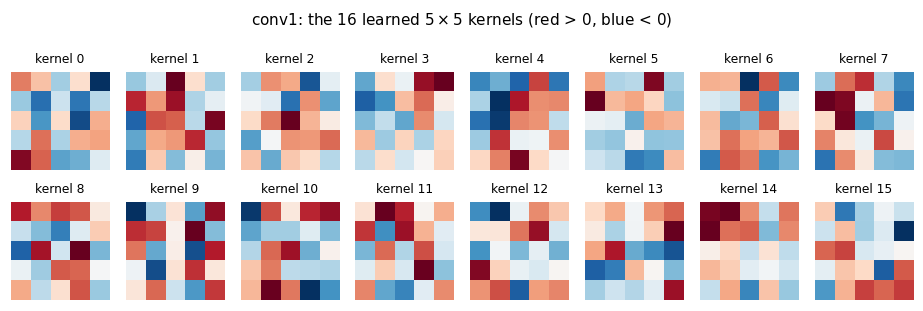

In [10]:
K1 = np.asarray(model.body.conv1.kernel[...])[:, :, 0, :]     # (5, 5, 16): drop the input-channel axis
fig, axs = plt.subplots(2, 8, figsize=(8.5, 3.0))
for k, ax in enumerate(axs.flat):
    v = np.abs(K1[:, :, k]).max()
    ax.imshow(K1[:, :, k], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"kernel {k}", fontsize=8); noframe(ax)
fig.suptitle("conv1: the 16 learned $5\\times5$ kernels (red > 0, blue < 0)", fontsize=10)
plt.tight_layout(); plt.show()

### 3.2 Feature maps from intermediate outputs

A **feature map** is the output of one channel of a convolutional layer: an image showing where in the input the corresponding pattern was found. `model(x)` returns only the logits. JAX has no forward hooks; there are two ways to obtain intermediate outputs.

The first is to call the submodules step by step. The layers are ordinary attributes, so we repeat the forward pass of `Body.__call__` explicitly and keep what we need. This is fully explicit and works for anything; the price is that the forward pass is coded twice.

The second is `nnx.capture`. `nnx.capture(model, nnx.Intermediate, method_outputs=nnx.Intermediate)` wraps the model; calling it returns the logits *and* a `State` with the output of every submodule's `__call__`, under paths such as `body/conv1/__call__`. Only module outputs are recorded: here `conv1`, `conv2` are captured *before* the ReLU (the ReLU is a function call inside `Body.__call__`, not a module), so we apply the ReLU ourselves. (A model can also record arbitrary values explicitly with `self.sow(nnx.Intermediate, "name", value)` inside `__call__`, collected by the same `nnx.capture`.)

After the ReLU the maps have shapes `(1, 28, 28, 16)` for conv1 and `(1, 14, 14, 32)` for conv2. Both ways must give the same arrays; the cell asserts this and prints "way 1 and way 2 agree", with way 1 the explicit forward pass and way 2 `nnx.capture`.

In [11]:
i_img = int(np.flatnonzero(np.asarray(ys_te) == 3)[0])     # the first test image of a 3
x_one = Xs_te[i_img:i_img + 1]                              # (1, 28, 28, 1): a batch of one image

# way 1: the forward pass of Body, step by step
b = model.body
relu1 = nnx.relu(b.conv1(x_one))                            # (1, 28, 28, 16)
relu2 = nnx.relu(b.conv2(b.pool1(relu1)))                   # (1, 14, 14, 32)

# way 2: capture the outputs of all submodules
logits, inter = nnx.capture(model, nnx.Intermediate, method_outputs=nnx.Intermediate)(x_one)
captured = flatten_dict(nnx.to_pure_dict(inter), sep="/")
print("captured outputs:", {k: v[0].shape for k, v in captured.items()})
c1 = nnx.relu(captured["body/conv1/__call__"][0])           # each entry is a tuple of the recorded values
c2 = nnx.relu(captured["body/conv2/__call__"][0])

assert relu1.shape == (1, 28, 28, 16) and relu2.shape == (1, 14, 14, 32)
assert jnp.allclose(relu1, c1) and jnp.allclose(relu2, c2)
features = {"relu1": relu1, "relu2": relu2}
print("way 1 and way 2 agree:", True)
print("predicted digit:", int(logits.argmax()), "| true digit:", int(ys_te[i_img]))
for k, v in features.items():
    print(f"{k}: shape {v.shape}, fraction of positive (active) entries {float((v > 0).mean()):.3f}")

captured outputs: {'__call__': (1, 5), 'body/__call__': (1, 1568), 'body/conv1/__call__': (1, 28, 28, 16), 'body/conv2/__call__': (1, 14, 14, 32), 'head/__call__': (1, 5), 'head/fc/__call__': (1, 64), 'head/out/__call__': (1, 5)}


way 1 and way 2 agree: True
predicted digit: 3 | true digit: 3


relu1: shape (1, 28, 28, 16), fraction of positive (active) entries 0.584
relu2: shape (1, 14, 14, 32), fraction of positive (active) entries 0.554


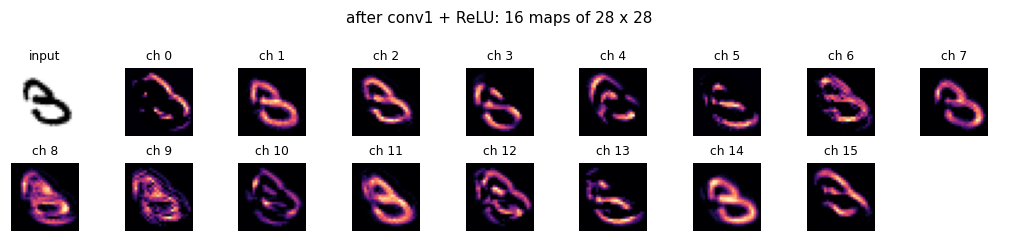

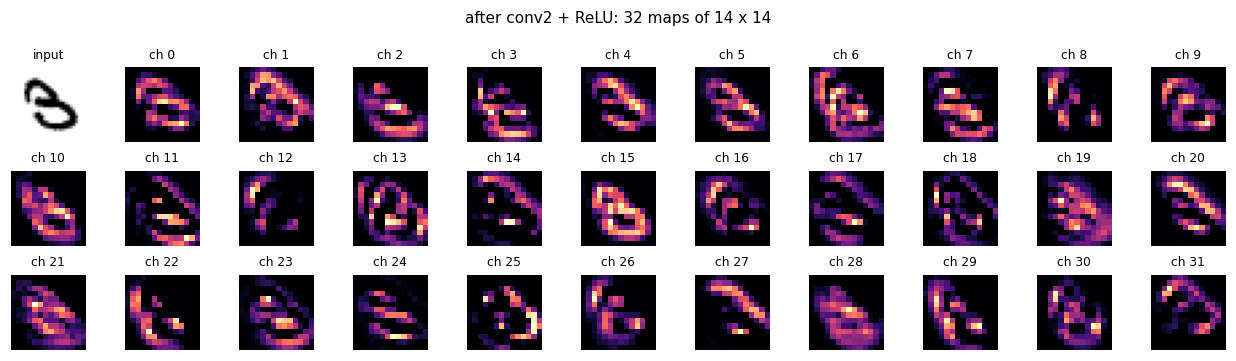

In [12]:
def show_maps(maps, ncols, title, img):
    # maps: (C, H, W); the input image is shown in the first panel
    C = maps.shape[0]
    nrows = int(np.ceil((C + 1) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.05 * ncols, 1.1 * nrows))
    axs = axs.flat
    axs[0].imshow(img, cmap="gray_r"); axs[0].set_title("input", fontsize=8)
    for c in range(C):
        axs[c + 1].imshow(maps[c], cmap="magma"); axs[c + 1].set_title(f"ch {c}", fontsize=8)
    for ax in axs: noframe(ax)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

img = np.asarray(x_one[0, :, :, 0])
# channels last -> channels first for plotting: (H, W, C) -> (C, H, W)
show_maps(np.asarray(features["relu1"][0]).transpose(2, 0, 1), 9, "after conv1 + ReLU: 16 maps of 28 x 28", img)
show_maps(np.asarray(features["relu2"][0]).transpose(2, 0, 1), 11, "after conv2 + ReLU: 32 maps of 14 x 14", img)

Most first-layer maps are filtered copies of the digit. In several of them only one side of the strokes, or only the strokes of one orientation, light up: a kernel with adjacent positive (red) and negative (blue) regions in Section 3.1 responds to a change of brightness in one direction, i.e. it is an oriented edge detector. Other maps respond to the background next to the ink. Second-layer maps have half the resolution, and each channel combines all 16 first-layer maps; the channels respond to more specific configurations, such as strokes of one direction in one part of the digit, and some are sparse for this image. This is the hierarchy of Lecture 4: local, generic patterns (edges, stroke directions) in the first layer, and combinations of them, more specific to the task, deeper in the network.

<hr/>
## 4. Model surgery

All operations of this section create new models from pieces of the trained one. One rule matters throughout: **NNX modules are objects with reference semantics**, like PyTorch modules. `nnx.Sequential(model.body, ...)` contains *the same* `body` object; training the new model would also change `model`. Use `nnx.clone` whenever the original must stay intact.

### 4.1 Cutting the network: a feature extractor

`model.body` alone maps images to feature vectors of 1568 numbers, `(N, 28, 28, 1) → (N, 1568)`. A Flax module cannot be sliced like `nn.Sequential`; a partial forward pass is implemented as a short function that calls the submodules: `feature_maps` stops before the flattening and returns the 32 feature maps, `(N, 7, 7, 32)`; `dense_features` applies the dense layer and ReLU of the head to the body's output and gives the 64 features of the next level, `(N, 64)`.

We compute both kinds of features for 2000 test images of the source digits 0–4 and 2000 of the unseen digits 5–9 and count active units (positive after the ReLU). A unit that is zero for every image ("dead" unit) carries no information about these images. Features that stay active and varied for 5–9 are candidates for re-use in Section 5.

In [13]:
extractor = model.body                                      # (N,28,28,1) -> (N,1568); the same object as in `model`

def feature_maps(body, x):
    # conv1 ... pool2: (N,28,28,1) -> (N,7,7,32)
    return body.pool2(nnx.relu(body.conv2(body.pool1(nnx.relu(body.conv1(x))))))

def dense_features(head, h):
    # fc + ReLU: (N,1568) -> (N,64)
    return nnx.relu(head.fc(h))

m_src = feature_maps(model.body, Xs_te[:2000])              # (2000, 7, 7, 32)
feats = {"digits 0-4 (seen)  ": extractor(Xs_te[:2000]),   # (2000, 1568)
         "digits 5-9 (unseen)": extractor(Xt_te[:2000])}
dense = {k: dense_features(model.head, f) for k, f in feats.items()}   # (2000, 64)
assert m_src.shape == (2000, 7, 7, 32) and feats["digits 0-4 (seen)  "].shape == (2000, 1568)
print("feature maps:", m_src.shape, "| body features:", feats["digits 0-4 (seen)  "].shape,
      "| dense features:", dense["digits 0-4 (seen)  "].shape)

def activity(f):
    active = (f > 0).astype(jnp.float32)
    return float(active.mean()), int((active.sum(0) == 0).sum())

for k in feats:
    a1, d1 = activity(feats[k]); a2, d2 = activity(dense[k])
    print(f"{k}: body features: active fraction {a1:.3f}, never active {d1:4d} of 1568 | "
          f"dense features: active fraction {a2:.3f}, never active {d2:2d} of 64")
f_tgt = feats["digits 5-9 (unseen)"]

feature maps: (2000, 7, 7, 32) | body features: (2000, 1568) | dense features: (2000, 64)


digits 0-4 (seen)  : body features: active fraction 0.722, never active    1 of 1568 | dense features: active fraction 0.599, never active 15 of 64
digits 5-9 (unseen): body features: active fraction 0.728, never active    3 of 1568 | dense features: active fraction 0.624, never active 16 of 64


### 4.2 Trained body, new head

For the digits 5–9 we need a network with the trained body and a *new*, randomly initialised head with 5 outputs. We create a fresh `SmallCNN(n_classes=5)` and copy the body's parameters with `nnx.update(new.body, nnx.state(model.body))`. This puts the trained arrays into the new body's variables; the variables themselves are separate, so training `new` later replaces arrays in `new` only (JAX arrays are immutable, so sharing them is harmless).

The new body should give the same feature vectors as the trained one, and the cell confirms it. The new head is random, so the accuracy on the digits 5–9 should be near chance level, $1/5=0.2$.

In [14]:
new = SmallCNN(5, rngs=nnx.Rngs(1))
nnx.update(new.body, nnx.state(model.body))                 # copy the trained body; the head stays random
assert jnp.array_equal(new.body(Xt_te[:2000]), f_tgt)       # identical features
assert new.body.conv1.kernel is not model.body.conv1.kernel # separate variables: no sharing
print("new body gives identical features:", True)
print(f"accuracy on digits 5-9 with the untrained head: {accuracy(new, Xt_te, yt_te):.3f} (chance level 0.2)")

# the pitfall: building a model from the *same* module object shares the parameters
shared = nnx.Sequential(model.body, nnx.Linear(1568, 5, rngs=nnx.Rngs(0)))
print("nnx.Sequential(model.body, ...) shares model.body:", shared.layers[0] is model.body,
      "| after nnx.clone:", nnx.clone(model.body) is model.body)

new body gives identical features: True


accuracy on digits 5-9 with the untrained head: 0.243 (chance level 0.2)


nnx.Sequential(model.body, ...) shares model.body: True | after nnx.clone: False


### 4.3 Inserting a layer

We insert an extra dense layer, $64\to64$ followed by a ReLU, inside the head, between the ReLU after `fc` and `out`. If it is initialised as the identity ($K=I$, $b=0$), the network computes exactly the same function as before: its input $h$ is non-negative (it comes out of a ReLU), so $\mathrm{ReLU}(hI+0)=h$. This is a useful way to enlarge a trained network without losing what it knows; training can then move the new layer away from the identity.

`nnx.Sequential(f1, f2, ...)` chains modules and plain functions (such as `nnx.relu`). Shapes: body `(N,1568)` → fc, ReLU `(N,64)` → extra, ReLU `(N,64)` → out `(N,5)`. The parameter count grows by $64\cdot64+64=4160$.

In [15]:
extra = nnx.Linear(64, 64, rngs=nnx.Rngs(3))
extra.kernel[...] = jnp.eye(64)                             # put new arrays into the variables
extra.bias[...] = jnp.zeros(64)

deeper = nnx.Sequential(nnx.clone(model.body),              # copies: `model` stays untouched
                        nnx.clone(model.head.fc), nnx.relu,
                        extra, nnx.relu,                    # the inserted layer
                        nnx.clone(model.head.out))
same = bool(jnp.allclose(deeper(Xs_te), model(Xs_te)))
assert same
print("deeper model, logits equal to the original:", same)
print("parameters: original", n_params(nnx.state(model, nnx.Param)), "| deeper", n_params(nnx.state(deeper, nnx.Param)))

deeper model, logits equal to the original: True
parameters: original 105797 | deeper 109957


### 4.4 Replacing a layer

A layer can be exchanged by assigning a new module (or function) to its attribute, `net.body.pool1 = partial(nnx.avg_pool, ...)`. The replacement must produce an output of the same shape, otherwise the next layer fails. The rest of the network was trained for the *old* layer, so its accuracy changes. We try two replacements on copies of the trained model. The first replaces max-pooling by average-pooling in `pool1`, which gives the same shape `(N,14,14,16)` but different numbers. The second replaces `conv1` by a new, randomly initialised convolution of the same shape, so that everything after it receives inputs it was never trained on.

In [16]:
net_avg = nnx.clone(model)
net_avg.body.pool1 = partial(nnx.avg_pool, window_shape=(2, 2), strides=(2, 2))   # replace by name
net_rnd = nnx.clone(model)
net_rnd.body.conv1 = nnx.Conv(1, 16, kernel_size=(5, 5), padding="SAME", rngs=nnx.Rngs(2))   # fresh random kernels
print("pool1:", net_avg.body.pool1.func.__name__, "| conv1 kernel:", net_rnd.body.conv1.kernel[...].shape)
print(f"test accuracy (digits 0-4): original {accuracy(model, Xs_te, ys_te):.4f} | "
      f"pool1 -> average {accuracy(net_avg, Xs_te, ys_te):.4f} | conv1 re-initialised {accuracy(net_rnd, Xs_te, ys_te):.4f}")

pool1: avg_pool | conv1 kernel: (5, 5, 1, 16)


test accuracy (digits 0-4): original 0.9909 | pool1 -> average 0.9910 | conv1 re-initialised 0.5166


Average pooling changes the numbers passed on but keeps their meaning (the same channels, the same positions), so the accuracy hardly changes. A re-initialised first layer destroys the meaning of all 16 channels for the layers after it, and the accuracy falls far: a trained network is a chain in which each layer is adapted to the layers before it.

<hr/>
## 5. Freezing and transfer learning

### 5.1 The target task with few labels

The new task is to classify the digits 5–9, with only a few labelled images, $n$ per class. **Transfer learning** re-uses the body trained on 0–4: strokes, edges and loops are common to all digits, so the convolutional features of Section 4.1 may also help for 5–9. We compare three strategies with the same number of gradient steps in total (300, minibatches of $\min(64, 5n)$ images, Adam):

| | initial body | trained parameters | steps | learning rate |
|---|---|---|---|---|
| (a) random initialisation | random | all | 300 | $10^{-3}$ |
| (b) frozen body | trained on 0–4 | head only | 200 | $10^{-3}$ |
| (c) fine-tuning | the result of (b) | all | +100 | body $10^{-4}$, head $3\cdot10^{-4}$ |

In (c) the learning rate is smaller: the body is already trained, and large steps driven by a few hundred images would overwrite it (and overfit). The labelled subset and the minibatches are drawn with NumPy generators with the same seeds as in Lab 003a, so both notebooks use exactly the same images. Below we first run the three strategies in detail for $n=100$ images per class (500 labelled images), and in Section 5.5 for several $n$.

In [17]:
def labelled_subset(n_per_class, seed):
    # n_per_class images of each target class, drawn from the pool without replacement
    rng = np.random.default_rng(seed)
    y = np.asarray(yt_pool)
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), n_per_class, replace=False) for c in range(5)])
    return Xt_pool[idx], yt_pool[idx]

def train_steps(model, optimizer, step_fn, X, y, steps, seed):
    # `steps` optimiser steps on minibatches of min(64, len(X)) images drawn at random
    rng = np.random.default_rng(seed)
    bs = min(64, len(X))
    for _ in range(steps):
        idx = rng.choice(len(X), bs, replace=False)
        loss = step_fn(model, optimizer, X[idx], y[idx])
    return float(loss)

def transfer_model(seed):
    # trained body (copied), new random head with 5 outputs
    m = SmallCNN(5, rngs=nnx.Rngs(seed))
    nnx.update(m.body, nnx.state(model.body))
    return m

X_lab, y_lab = labelled_subset(100, seed=0)
assert X_lab.shape == (500, 28, 28, 1) and np.array_equal(np.bincount(np.asarray(y_lab)), np.full(5, 100))
print("labelled set:", X_lab.shape, "| images per class:", np.bincount(np.asarray(y_lab)).tolist())

labelled set: (500, 28, 28, 1) | images per class: [100, 100, 100, 100, 100]


### 5.2 Training from a random initialisation

In strategy (a) all 105 797 parameters start random and are trained on the 500 labelled images only. This is the baseline against which transfer is measured.

In [18]:
net_a = SmallCNN(5, rngs=nnx.Rngs(10))
opt = nnx.Optimizer(net_a, optax.adam(1e-3), wrt=nnx.Param)
last = train_steps(net_a, opt, step_all, X_lab, y_lab, steps=300, seed=0)
acc_a = accuracy(net_a, Xt_te, yt_te)
print(f"(a) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_a:.4f}")

(a) last minibatch loss 0.0022 | test accuracy on digits 5-9: 0.9443


### 5.3 Frozen body with a new head

Strategy (b) keeps the trained body fixed. In JAX/Flax the mechanism is the filter `head_only = nnx.All(nnx.Param, nnx.PathContains("head"))`, used in two places. In `nnx.Optimizer(net, optax.adam(1e-3), wrt=head_only)` the optimiser holds Adam's state only for the head's parameters and updates only them. In the gradient call, `nnx.DiffState(0, head_only)` (inside `step_head = make_train_step(head_only)`) makes JAX differentiate only with respect to the head, so no gradient of the body is ever computed, which also saves computation.

Nothing in the model is marked as frozen; the same model trained with `step_all` and an optimiser with `wrt=nnx.Param` would change everywhere.

To make sure the freezing works, we copy the body's parameters before training and assert afterwards that they are bit-for-bit unchanged, while the head did change.

In [19]:
net_b = transfer_model(seed=10)
step_head = make_train_step(head_only)                        # gradient w.r.t. the head only
tr, fr = count_params(net_b, head_only)
print(f"trainable parameters: {tr} (head) | frozen parameters: {fr} (body)")
assert tr == (1568 * 64 + 64) + (64 * 5 + 5)

body_before = jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(net_b.body, nnx.Param)))   # NumPy copies, for the check
head_before = np.array(net_b.head.fc.kernel[...])
opt = nnx.Optimizer(net_b, optax.adam(1e-3), wrt=head_only)   # the optimiser sees only the head
print("numbers stored in Adam's state (two moments per trained parameter, plus a step counter):", n_params(opt.opt_state))
last = train_steps(net_b, opt, step_head, X_lab, y_lab, steps=200, seed=0)

body_after = nnx.to_pure_dict(nnx.state(net_b.body, nnx.Param))
assert all(jax.tree.leaves(jax.tree.map(np.array_equal, body_before, body_after))), "frozen body changed!"
assert not np.array_equal(head_before, net_b.head.fc.kernel[...])
print("body parameters unchanged:", True, "| head changed:", True)
acc_b = accuracy(net_b, Xt_te, yt_te)
print(f"(b) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_b:.4f}")

trainable parameters: 100741 (head) | frozen parameters: 5056 (body)
numbers stored in Adam's state (two moments per trained parameter, plus a step counter): 201483


body parameters unchanged: True | head changed: True


(b) last minibatch loss 0.0289 | test accuracy on digits 5-9: 0.9517


The place of the cut matters. Section 3 suggested that early layers compute generic patterns and later layers task-specific ones. We test this directly by cutting one layer later: the trained dense layer `head.fc` is kept frozen as well, and only a new output layer (325 parameters) is trained on the same 500 images, with the same 200 steps. The filter `nnx.PathContains("out")` selects the output layer only.

In [20]:
net_b2 = nnx.clone(model)                                      # trained body and trained dense layer
net_b2.head.out = nnx.Linear(64, 5, rngs=nnx.Rngs(10))         # new output layer
out_only = nnx.All(nnx.Param, nnx.PathContains("out"))
print("trainable / frozen parameters:", count_params(net_b2, out_only))
train_steps(net_b2, nnx.Optimizer(net_b2, optax.adam(1e-3), wrt=out_only), make_train_step(out_only),
            X_lab, y_lab, steps=200, seed=0)
acc_b2 = accuracy(net_b2, Xt_te, yt_te)
print(f"test accuracy on digits 5-9: cut after the convolutional body {acc_b:.4f} | cut after the dense layer {acc_b2:.4f}")

trainable / frozen parameters: (325, 105472)


test accuracy on digits 5-9: cut after the convolutional body 0.9517 | cut after the dense layer 0.7149


The same freezing can also be obtained with `optax.multi_transform`. This alternative keeps the gradient and the optimiser over *all* parameters but gives the optimiser different rules for different parts. Every parameter receives a **label** (`"body"` or `"head"`), computed from its path by `jax.tree_util.tree_map_with_path`; `optax.multi_transform({"body": rule, "head": rule}, labels)` applies to each parameter the rule of its label. With `optax.set_to_zero()` for the body, the body's updates are zero. The gradient of the body is still computed (and then discarded), so this route costs more computation than the `wrt` filter; its advantage is that the same mechanism also gives each part its own learning rate, used in (c). The cell runs 20 steps on a copy of the model and checks that the body stays unchanged while the head changes.

In [21]:
def part_labels(params):
    # "head" for every parameter whose path starts with head, "body" otherwise
    return jax.tree_util.tree_map_with_path(lambda path, _: "head" if path[0].key == "head" else "body", params)

print("labels:", flatten_dict(nnx.to_pure_dict(part_labels(nnx.state(net_b, nnx.Param))), sep="/"))

tmp = nnx.clone(net_b)
tx = optax.multi_transform({"body": optax.set_to_zero(), "head": optax.adam(1e-3)}, part_labels)
opt_tmp = nnx.Optimizer(tmp, tx, wrt=nnx.Param)                # all parameters are passed to the optimiser ...
train_steps(tmp, opt_tmp, step_all, X_lab, y_lab, steps=20, seed=5)   # ... and all gradients are computed
same_body = all(jax.tree.leaves(jax.tree.map(np.array_equal, nnx.to_pure_dict(nnx.state(net_b.body, nnx.Param)),
                                                              nnx.to_pure_dict(nnx.state(tmp.body, nnx.Param)))))
assert same_body and not np.array_equal(tmp.head.fc.kernel[...], net_b.head.fc.kernel[...])
print("multi_transform with set_to_zero: body unchanged:", same_body, "| head changed:", True)

labels: {'body/conv1/bias': 'body', 'body/conv1/kernel': 'body', 'body/conv2/bias': 'body', 'body/conv2/kernel': 'body', 'head/fc/bias': 'head', 'head/fc/kernel': 'head', 'head/out/bias': 'head', 'head/out/kernel': 'head'}


multi_transform with set_to_zero: body unchanged: True | head changed: True


### 5.4 Fine-tuning with a smaller learning rate

Strategy (c) continues from the result of (b) (a copy, `nnx.clone(net_b)`) and trains all parameters for 100 more steps. Per-part learning rates are the `optax.multi_transform` of the previous cell with two Adam rules: the body moves with $10^{-4}$, the head with $3\cdot10^{-4}$. This is the counterpart of PyTorch's parameter groups. The optimiser now has `wrt=nnx.Param` and the step is `step_all`, so the body is no longer frozen.

In [22]:
net_c = nnx.clone(net_b)                                        # (b) stays available
tx = optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(3e-4)}, part_labels)
opt = nnx.Optimizer(net_c, tx, wrt=nnx.Param)
print("trainable / frozen parameters:", count_params(net_c, nnx.Param))
last = train_steps(net_c, opt, step_all, X_lab, y_lab, steps=100, seed=1)
assert not np.array_equal(net_c.body.conv1.kernel[...], net_b.body.conv1.kernel[...])   # the body did move this time
acc_c = accuracy(net_c, Xt_te, yt_te)
print(f"(c) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_c:.4f}")
print(f"\nn = 100 images per class: (a) {acc_a:.4f} | (b) {acc_b:.4f} | (c) {acc_c:.4f}")

trainable / frozen parameters: (105797, 0)


(c) last minibatch loss 0.0044 | test accuracy on digits 5-9: 0.9525

n = 100 images per class: (a) 0.9443 | (b) 0.9517 | (c) 0.9525


### 5.5 Dependence on the number of labelled images

A single value of $n$ does not show when transfer pays off. We therefore repeat (a), (b), (c) for $n\in\{10, 30, 100, 300\}$ images per class, i.e. 50 to 1500 labelled images, each with 3 different labelled subsets (seeds 0, 1, 2). The figure shows the mean test accuracy on all 4861 test images of the digits 5–9; the error bars are the standard deviation over the 3 subsets.

In [23]:
def run_all(n_per_class, seed):
    X, y = labelled_subset(n_per_class, seed)
    m = SmallCNN(5, rngs=nnx.Rngs(100 + seed))                 # (a) random initialisation
    train_steps(m, nnx.Optimizer(m, optax.adam(1e-3), wrt=nnx.Param), step_all, X, y, 300, seed)
    acc = [accuracy(m, Xt_te, yt_te)]
    m = transfer_model(100 + seed)                              # (b) frozen body
    train_steps(m, nnx.Optimizer(m, optax.adam(1e-3), wrt=head_only), step_head, X, y, 200, seed)
    acc.append(accuracy(m, Xt_te, yt_te))
    tx = optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(3e-4)}, part_labels)
    train_steps(m, nnx.Optimizer(m, tx, wrt=nnx.Param), step_all, X, y, 100, seed + 1000)   # (c), continues from (b)
    acc.append(accuracy(m, Xt_te, yt_te))
    return acc

t0 = time.time()
N_PER_CLASS = [10, 30, 100, 300]
SEEDS = [0, 1, 2]
acc = np.array([[run_all(n, s) for s in SEEDS] for n in N_PER_CLASS])   # (n values, seeds, strategies)
print(f"sweep time: {time.time() - t0:.0f} s\n")
print("test accuracy on digits 5-9, mean ± std over 3 labelled subsets")
print(f"{'n per class':>12s} {'(a) random init':>18s} {'(b) frozen body':>18s} {'(c) fine-tuned':>18s}")
for i, n in enumerate(N_PER_CLASS):
    print(f"{n:12d} " + " ".join(f"{acc[i, :, j].mean():11.4f} ± {acc[i, :, j].std():.4f}" for j in range(3)))

sweep time: 256 s

test accuracy on digits 5-9, mean ± std over 3 labelled subsets
 n per class    (a) random init    (b) frozen body     (c) fine-tuned
          10      0.8513 ± 0.0140      0.8727 ± 0.0233      0.8722 ± 0.0227
          30      0.9112 ± 0.0111      0.9281 ± 0.0079      0.9294 ± 0.0078
         100      0.9480 ± 0.0019      0.9556 ± 0.0027      0.9573 ± 0.0012
         300      0.9727 ± 0.0049      0.9698 ± 0.0028      0.9720 ± 0.0026


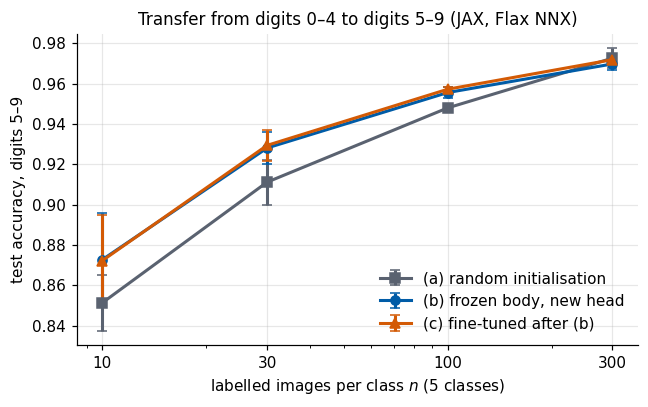

In [24]:
labels = ["(a) random initialisation", "(b) frozen body, new head", "(c) fine-tuned after (b)"]
colors, markers = [UJGray, UJBlue, DSOrange], ["s", "o", "^"]
fig, ax = plt.subplots(figsize=(6, 3.8))
for j in range(3):
    m, s = acc[:, :, j].mean(1), acc[:, :, j].std(1)
    ax.errorbar(N_PER_CLASS, m, yerr=s, color=colors[j], marker=markers[j], ms=6, lw=2, capsize=3, label=labels[j])
ax.set_xscale("log"); ax.set_xticks(N_PER_CLASS); ax.set_xticklabels(N_PER_CLASS)
ax.set_xlabel("labelled images per class $n$ (5 classes)")
ax.set_ylabel("test accuracy, digits 5–9")
ax.set_title("Transfer from digits 0–4 to digits 5–9 (JAX, Flax NNX)")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

For $n=30$ and $n=100$ images per class the trained body helps: (b) and (c) lie above (a) by more than the spread over the labelled subsets. For $n=10$ the mean is also higher, but the spread over subsets is of the same size as the difference. At $n=300$ the network trained from a random initialisation catches up: with enough labels it learns features for 5–9 by itself, while the frozen body keeps the features learned for 0–4. Fine-tuning (c) gives at most a small gain over (b) with these 100 extra steps.

The gains from transfer are modest here because the target task is easy: a small CNN trained from a random initialisation on 50 images already classifies most test digits correctly. The choice of the cut (Section 5.3) mattered much more: a frozen dense layer trained on 0–4 left far fewer correctly classified digits than the frozen convolutional body. Generic early features transfer; task-specific late features do not.

<hr/>
## 6. Correspondence between PyTorch and JAX/Flax NNX

The table collects every operation of this lab together with its counterpart in Lab 003b, for quick reference when moving between the two frameworks.

| operation | PyTorch | JAX / Flax NNX |
|---|---|---|
| image layout | `(N, C, H, W)` | `(N, H, W, C)` |
| conv kernel shape | `(out, in, kh, kw)` | `(kh, kw, in, out)` |
| dense weight shape | `weight: (out, in)`, $y=xW^T+b$ | `kernel: (in, out)`, $y=xK+b$ |
| save | `torch.save(model.state_dict(), "f.pt")` | `flat = flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")`; `np.savez("f.npz", **flat)` |
| load into fresh model | `fresh.load_state_dict(torch.load("f.pt", weights_only=True))` | `st = nnx.state(fresh, nnx.Param)`; `nnx.replace_by_pure_dict(st, unflatten_dict(dict(np.load("f.npz")), sep="/"))`; `nnx.update(fresh, st)` |
| list parameters | `for name, p in model.named_parameters()` | `flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")` |
| one layer's weights | `model.body.conv1.weight.detach().numpy()` | `np.asarray(model.body.conv1.kernel[...])` |
| set weights directly | `with torch.no_grad(): layer.weight.copy_(W)` | `layer.kernel[...] = W` |
| intermediate outputs | `layer.register_forward_hook(fn)`, `handle.remove()` | call submodules step by step, or `nnx.capture(model, nnx.Intermediate, method_outputs=nnx.Intermediate)(x)` |
| feature extractor | `model.body`, or slice `model.body[:6]` | `model.body`; a partial forward pass is implemented as a function |
| new head on trained body | `new.body.load_state_dict(model.body.state_dict())` | `nnx.update(new.body, nnx.state(model.body))` |
| copy a module | `copy.deepcopy(m)` | `nnx.clone(m)` |
| insert a layer | `nn.Sequential(body, extra, nn.ReLU(), head)` | `nnx.Sequential(body, extra, nnx.relu, head)` |
| replace a layer | `net.body.pool1 = nn.AvgPool2d(2)` | `net.body.pool1 = partial(nnx.avg_pool, window_shape=(2, 2), strides=(2, 2))` |
| freeze | `p.requires_grad_(False)`; optimiser gets `net.head.parameters()` | `nnx.Optimizer(net, tx, wrt=head_filter)` and `nnx.grad(..., argnums=nnx.DiffState(0, head_filter))`, or `optax.multi_transform` with `optax.set_to_zero()` for the body |
| where "frozen" lives | in the parameter (`requires_grad`) | in the optimiser and the gradient call (the model has no such flag) |
| per-part learning rates | parameter groups `[{"params": ..., "lr": ...}, ...]` | `optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(3e-4)}, labels)` |

The last cell prints the total run time of the notebook.

In [25]:
print(f"total run time of the notebook: {time.time() - t_start:.0f} s")

total run time of the notebook: 333 s
